# Step 1 : Frame the Problem



## 1. Business Question
What factors are associated with salary differences in data and AI jobs?

The goal is to explore how salary varies with job title, experience level, employment type, work arrangement, employee residence, company location, and company size.

## 2. Unit of Observation
One row represents one salary record for a job position.

Before analysis, check whether duplicate rows exist and whether multiple records represent different employees, different salary observations, or repeated entries.

## 3. Target Variable
- **Target:** `salary_in_usd`
- **Type:** Numeric (continuous)
- **Meaning:** Salary expressed in US dollars.

The primary objective is to understand salary distributions and identify factors associated with salary differences.

## 4. Time Column
- **Column:** `work_year`
- **Type:** Temporal / discrete year
- **Purpose:** Analyze salary trends across years and check whether comparisons are affected by changes over time.

## 5. Known Limitations
- The dataset's collection method and sampling process must be verified.
- The available records may not represent every data and AI professional or job market.
- Salary may depend on factors not included in the dataset, such as industry, education, and years of experience.
- `employee_residence` and `company_location` represent different geographic dimensions.
- The meaning and encoding of `remote_ratio` should be verified using the data dictionary.
- Currency conversion, salary period, and missing-value conventions should be checked before analysis.

## 6. Hypotheses
1. Senior-level roles tend to have higher salaries than entry-level roles.
2. Salary distributions differ across job titles.
3. Salary varies by company location and employee residence.
4. Salary distributions differ across company sizes.
5. Remote work arrangements are associated with salary differences.

These are hypotheses to investigate, not conclusions.

## Initial Analysis Plan
1. Inspect column types, missing values, and duplicate records.
2. Validate category definitions and salary units.
3. Examine salary distributions and outliers.
4. Compare salary across experience levels, job titles, locations, and company sizes.
5. Investigate year-over-year salary trends.
6. If predictive modeling is required, define the prediction objective and prevent data leakage.


In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Step 2 : Take a First Look

In [22]:
df = pd.read_csv("../data/ds_salaries.csv")

df.shape

df.head() 

df.sample(5, random_state=0) 

df.info() 

df.nunique() 


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3755 entries, 0 to 3754
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           3755 non-null   int64 
 1   experience_level    3755 non-null   object
 2   employment_type     3755 non-null   object
 3   job_title           3755 non-null   object
 4   salary_in_usd       3755 non-null   int64 
 5   employee_residence  3755 non-null   object
 6   remote_ratio        3755 non-null   int64 
 7   company_location    3755 non-null   object
 8   company_size        3755 non-null   object
dtypes: int64(3), object(6)
memory usage: 264.2+ KB


work_year                4
experience_level         4
employment_type          4
job_title               93
salary_in_usd         1035
employee_residence      78
remote_ratio             3
company_location        72
company_size             3
dtype: int64

# Convert categorical columns to category dtype

In [23]:
categorical_columns = [
    "experience_level",
    "employment_type",
    "job_title",
    "employee_residence",
    "company_location",
    "company_size",
]

for col in categorical_columns:
    df[col] = df[col].astype("category")

# Verify the changes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3755 entries, 0 to 3754
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   work_year           3755 non-null   int64   
 1   experience_level    3755 non-null   category
 2   employment_type     3755 non-null   category
 3   job_title           3755 non-null   category
 4   salary_in_usd       3755 non-null   int64   
 5   employee_residence  3755 non-null   category
 6   remote_ratio        3755 non-null   int64   
 7   company_location    3755 non-null   category
 8   company_size        3755 non-null   category
dtypes: category(6), int64(3)
memory usage: 118.7 KB


In [24]:

df["remote_ratio"] = df["remote_ratio"].map({
    0: "On-site",
    50: "Hybrid",
    100: "Fully remote",
}).astype("category")


df["remote_ratio"].value_counts(dropna=False)


remote_ratio
On-site         1923
Fully remote    1643
Hybrid           189
Name: count, dtype: int64

# Step 3 : Assess Data Quality

In [25]:
# Missing values
miss = df.isna().mean().mul(100).round(1).sort_values(ascending=False)
print(miss[miss > 0])

# Duplicates
print("Rows before:", len(df))

df = df.drop_duplicates()

print("Rows after:", len(df))
print("Remaining duplicates:", df.duplicated().sum())

Series([], dtype: float64)
Rows before: 3755
Rows after: 2584
Remaining duplicates: 0


# Clean inconsistent text labels


In [26]:
text_columns = [
    "experience_level",
    "employment_type",
    "job_title",
    "employee_residence",
    "company_location",
    "company_size"
]

for col in text_columns:
    df[col] = df[col].str.strip()

# Standardize categorical codes
for col in [
    "experience_level",
    "employment_type",
    "employee_residence",
    "company_location",
    "company_size"
]:
    df[col] = df[col].str.upper()

# Check unique values
for col in text_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


experience_level:
experience_level
SE    1554
MI     664
EN     270
EX      96
Name: count, dtype: int64

employment_type:
employment_type
FT    2547
PT      17
CT      10
FL      10
Name: count, dtype: int64

job_title:
job_title
Data Engineer                598
Data Scientist               538
Data Analyst                 396
Machine Learning Engineer    206
Analytics Engineer            91
                            ... 
Principal Data Architect       1
Head of Machine Learning       1
Cloud Data Architect           1
Staff Data Scientist           1
Finance Data Analyst           1
Name: count, Length: 93, dtype: int64

employee_residence:
employee_residence
US    1893
GB     150
CA      81
IN      70
DE      47
      ... 
RS       1
NZ       1
MD       1
LU       1
MT       1
Name: count, Length: 78, dtype: int64

company_location:
company_location
US    1929
GB     155
CA      83
IN      57
DE      55
      ... 
CN       1
NZ       1
CL       1
MD       1
MT       1
Name: count

# Step 4 : Study Numeric Variables One at a Time

,count,mean,std,min,25%,50%,75%,max
work_year,2584.0,2022.301084,0.749179,2020.0,2022.0,2022.0,2023.0,2023.0
salary_in_usd,2584.0,133409.280186,67136.837329,5132.0,84975.0,130000.0,175000.0,450000.0


work_year       -0.97
salary_in_usd    0.62
dtype: float64

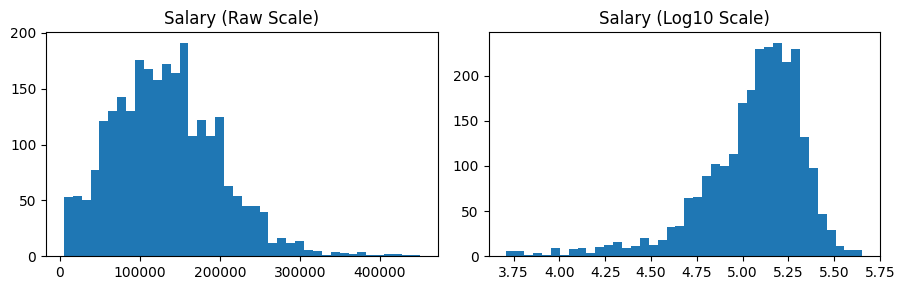

remote_ratio
Fully remote    1211
On-site         1186
Hybrid           187
Name: count, dtype: int64

In [ ]:
# Numerical columns
num_cols = ["work_year", "salary_in_usd"]

# Descriptive statistics
display(df[num_cols].describe().T)

# Skewness
display(df[num_cols].skew().round(2))

# Salary distribution: raw vs log scale
salary = df["salary_in_usd"].dropna()
salary = salary[salary > 0]

fig, ax = plt.subplots(1, 2, figsize=(9, 3))

ax[0].hist(salary, bins=40)
ax[0].set_title("Salary (Raw Scale)")

ax[1].hist(np.log10(salary), bins=40)
ax[1].set_title("Salary (Log10 Scale)")

plt.tight_layout()
plt.show()

# Categorical distribution of remote work
display(df["remote_ratio"].value_counts(dropna=False))